# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot SSH anomalies over all time by pattern

**Notebook by Alice DuVivier - October 2026**

In [1]:
import pandas as pd
from minisom import MiniSom, asymptotic_decay
import xarray as xr
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import seaborn as sns
import pickle
import dask

In [2]:
# set path where the som finalist files are
dir_base = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/'

### Get grid data

In [3]:
# load grid files for plotting

dir_grid = '/glade/u/home/duvivier/masks/'
file_in = 'POP_tx0.1v3_grid.nc'
ds_grid = xr.open_mfdataset(dir_grid+file_in, decode_times=False)    

# clip global data to match other files - do in two steps because that's how I originally clipped data
# Step 1: clip to full Arctic Region
ds_grid_sub = ds_grid.isel(nlat=slice(1700,2250)).isel(nlon=slice(2700,3300))

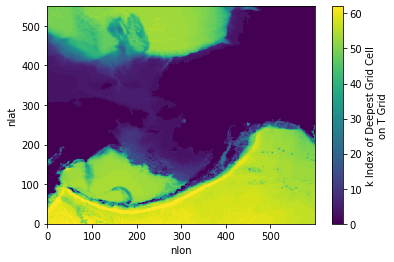

In [4]:
ds_grid_sub.KMT.plot()

In [5]:
# grab lat and lon data
lat2d = ds_grid_sub.TLAT
lon2d = ds_grid_sub.TLONG
# convert to a 0-360 grid
lon2d = lon2d % 360

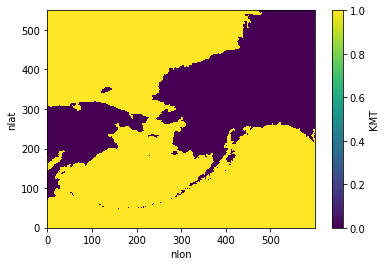

In [6]:
# grab KMT for
ocean = ds_grid_sub.KMT > 0
ocean.plot()

## Load training data to interpret SOMs

In [7]:
# set input directory
dir_in = dir_base + 'som_training/'

In [8]:
def normalize_data(data):
    """
    Function for normalizing data prior to training using z-score
    """
    return (data - np.nanmean(data)) / np.nanstd(data)

In [9]:
# open file saved in earlier notebook (soms_antarctica-gettingdata.ipynb)
subset = xr.open_dataset(dir_in+'mesaclip_training_data_alaska_psl_autumn_decadal.nc')

# assign to numpy array object
subsetarray = subset['train_data'].values

# set data
data = normalize_data(subsetarray)

# set data input length
input_length = subsetarray.shape[1]    # using preprocessed data array; Number of the elements of the vectors in input.

## Set the parameter combinations for SOM finalists

In [10]:
# set paired values for possible winning maps based on Sammon maps evaluation
som_grid_rows    = [3, 4]    # (y-axis)
som_grid_cols    = [3, 4]    # (x-axis)
ranks            = [3, 45]
sigs             = [1.0, 1.0]
lrs              = [0.01, 0.005]
nitrs            = [250000, 50000]

## MANUAL CHANGING REQUIRED HERE ##
# select which set to plot
n = 0

In [11]:
# select info for input file (set above)
som_row = som_grid_rows[n]
som_col = som_grid_cols[n]
rank = ranks[n]
sig = sigs[n]
lr = lrs[n]
n_iter = nitrs[n]

In [12]:
# set the input name file from this
fin = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
print(fin)

som_alaska_psl_3x3_sig1.0_lr0.01_iter250000


## Load pickles of "winning" combos and make assessment plots

In [13]:
# open pickle
with open(dir_in+'pickles/psl_som/'+fin+'.p', 'rb') as infile:
    som = pickle.load(infile)

In [14]:
# double check qerror
qerr = som.quantization_error(data)
print('quantization error: '+str(qerr))

quantization error: 26.348131518266264


In [15]:
# create an empty dictionary using the rows and columns of SOM
keys = [i for i in product(range(som_row),range(som_col))]
winmap = {key: [] for key in keys}

In [16]:
# set frequencies
frequencies = 100.*((som.activation_response(data))/sum(sum(som.activation_response(data))))
#verify the total frequency is 100%
total = sum(sum(frequencies))

# grab the indices for the data within the SOM lattice
for i, x in enumerate(data):
    winmap[som.winner(x)].append(i) 

# create list of the dictionary keys
som_keys = list(winmap.keys())
print(f"Number of composite maps: {len(som_keys)}")
print(f"The rows and columns of the SOM lattice to use to grab SOM indexes:\n{[i for i in list(winmap.keys())]}")

Number of composite maps: 9
The rows and columns of the SOM lattice to use to grab SOM indexes:
[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]


## Load data to make composites
- not identical to training data so we can see larger area patterns

In [17]:
# set input directory
dir_in = dir_base + 'data_for_composites/'

var_in = 'SSH'

In [18]:
# Load data for larger area than only training area - set file name
ds1 = xr.open_dataset(dir_in+var_in+'_autumn_hist_decadal_alaska_cam_grid.nc',
                      chunks={'ensemble': 1, 'decades': 1})
ds2 = xr.open_dataset(dir_in+var_in+'_autumn_rcp60_decadal_alaska_cam_grid.nc',
                      chunks={'ensemble': 1, 'decades': 1})
# combine two time periods
ds = xr.concat([ds1, ds2], dim='decades', join='override')[var_in].astype('float32')

In [19]:
# make a node label for every day
dims = ('ensemble', 'decades', 'autumn_days')
shape = tuple(ds.sizes[d] for d in dims)
assert len(data) == np.prod(shape), 'training data and composite data have different lengths'

labels = np.full(np.prod(shape), -1)
for k, key in enumerate(som_keys):
    labels[winmap[key]] = k
node_da = xr.DataArray(labels.reshape(shape), dims=dims, name='node')

In [20]:
ds

<xarray.DataArray 'SSH' (ensemble: 9, decades: 15, autumn_days: 366, nlat: 550, nlon: 600)>
dask.array<concatenate, shape=(9, 15, 366, 550, 600), dtype=float32, chunksize=(1, 1, 366, 550, 600), chunktype=numpy.ndarray>
Coordinates:
  * ensemble  (ensemble) object '002' '003' '004' '005' ... '008' '009' '010'
    ULONG     (nlat, nlon) float64 160.1 160.2 160.3 160.4 ... -1.0 -1.0 -1.0
    ULAT      (nlat, nlon) float64 48.6 48.6 48.6 48.6 ... -1.0 -1.0 -1.0 -1.0
  * decades   (decades) int64 1950 1960 1970 1980 1990 ... 2060 2070 2080 2090
Dimensions without coordinates: autumn_days, nlat, nlon
Attributes:
    long_name:     Sea Surface Height
    units:         centimeter
    grid_loc:      2110
    cell_methods:  time: mean
    coordinates:   TLONG TLAT time

## Make node composite averages
- Over all time

In [21]:
# compute all node composites

# get seasonal climatology
clim = ds.mean(dim=list(dims))
# get node averages
node_mean = ds.groupby(node_da).mean()
# actually calculate
node_mean, clim = dask.compute(node_mean, clim)
# get anomalies
node_composite_all = node_mean - clim

/glade/work/duvivier/miniconda3/envs/antarctica_som_env/lib/python3.7/site-packages/xarray/core/indexing.py:1226: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]
/glade/work/duvivier/miniconda3/envs/antarctica_som_env/lib/python3.7/site-packages/xarray/core/indexing.py:1226: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...   

In [22]:
# convert data to m from cm
orig = node_composite_all
node_composite_all = node_composite_all/100.0

## Make Plots

In [23]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v4/'

In [24]:
## set colors
cmap_choice = plt.cm.get_cmap('coolwarm')

# set lat/lon bounds
lat_max = 72
lat_min = 52
lon_max = 218
lon_min = 182
lon_avg = 200

# set plotting info
units = 'm'

In [25]:
# set plotting limits
print(float(node_composite_all.min()))
print(float(node_composite_all.max()))

vmin_in = -0.4
vmax_in = 0.4 
ticks_1 = np.round(np.linspace(vmin_in, vmax_in, 9), 2)
print(ticks_1)

-0.36004146933555603
0.3582073152065277
[-0.4 -0.3 -0.2 -0.1  0.   0.1  0.2  0.3  0.4]


In [26]:
# set node names
node_names = ['0a', '0b', '0c', '1a', '1b', '1c', '2a', '2b', '2c']

### Plot anomaly composite maps over all time

In [ ]:
# set some of the plot info
fig, axs = plt.subplots(som_row, som_col, subplot_kw={'projection':ccrs.Stereographic(central_longitude=lon_avg)}, figsize=(14,12))

# set info for this plot
#ds_plot = node_composite_all
ds_plot = node_composite_all.where(node_composite_all != 0)
file_out = 'supp_fig_som_ssh_anomaly_composite_all_times.png'

# loop through the different maps to get the indices of training data that map there
for map_num in range(len(som_keys)):
    print('node: '+str(map_num))
    # grab the composite data that corresponds to those training times and node
    ds_sub = ds_plot.isel(node=map_num)

    # make plot for this node - note using .values converts from xarray to numpy array
    data_masked = ds_sub.where(ocean.values > 0.5)
    cs = axs[som_keys[map_num][0], som_keys[map_num][1]].pcolormesh(
        lon2d.values, lat2d.values, data_masked.values,
        vmin=vmin_in, vmax=vmax_in, cmap=cmap_choice, transform=ccrs.PlateCarree())
    # modify the plots
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_extent([lon_min,lon_max,lat_min,lat_max])
    axs[som_keys[map_num][0],som_keys[map_num][1]].coastlines(resolution='110m', color='0.25', linewidth=0.5, zorder=10)
    
    # plot titles
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_title('Pattern '+node_names[map_num], fontsize=12)
    
# colorbar stuff
cbar_ax = fig.add_axes([0.25,0.1,0.5,0.01]) 
cbar = fig.colorbar(cs, cax=cbar_ax, ticks=ticks_1[:], orientation='horizontal', extend='both')
cbar.ax.set_xticklabels(list(ticks_1))
cbar.ax.tick_params(labelsize=12)
cbar.set_label('SSH anomaly ('+units+')', fontsize=12)
    
# save figure
plt.savefig(file_out, bbox_inches='tight', dpi=200)
plt.savefig(dir_out+file_out, bbox_inches='tight', dpi=200)

### Plot Just pattern 2a

In [27]:
# set lat/lon bounds
lat_max = 70
lat_min = 55
lon_max = 210
lon_min = 185
lon_avg = 200

In [28]:
## box 1, Bering Sea
box1_latmin = 62
box1_latmax = 68
box1_lonmin = -173.
box1_lonmax = -160.

In [29]:
# set paired lists with name and lat/lon
# main villages
village_names_1 = ['Shishmaref','Nome','Unalakleet','Savoonga','Gambell']
village_lats_1 =  [66.257, 64.501, 63.879, 63.694,63.77611]
village_lons_1 =  [-166.072, -165.406, -160.790, -170.479,-171.70083]
village_shapes_1 = ["o","*","s","d","P"]
village_sizes_1 = [12, 17, 12, 13, 14]

# other villages names - 
# Utqiagvik, Wrainwright, Point Lay, Point Hope, Kivalina, Kotzebue, Deering, Wales, Teller, Brevig Mission, 
# Solomon, Golovin, Elim, Koyuk, Shaktoolik, St. Michaels, Stebbins, Kotlik, Emmonak, Alakanuk
# Nunam Iqua, Scammon Bay, Paimiut, Hooper Bay, Chevak, Newtok, Tununak, Umkumiut, Nunakauyarmiut
# Nightmute, Chefornak, Kipnuk, Kwigillingok, Kongiganak, Tuntutuliak, Eek, Kwinhagak, Platinum, Goodnews Bay, Togiak,
# Aleut Community of St. Paul, Aleut Community of St. George, Mekoryuk, Gambell, King Island, Little Diomede Island
village_lats_2 =  [71.29,70.638,69.7438,68.347052,67.7272,66.898331,66.07583,65.61222,65.26349,65.3347,\
                   64.55876,64.54333,64.6178,64.9311,64.3556,63.478526,63.51194,63.0358,62.7722,62.68889,\
                   62.516094,61.8425,61.70083,61.531111,61.52778,60.9428,60.5805,60.4996528,60.53381,\
                   60.49139,60.15907,59.9390,59.872266,59.953896,60.3426,60.218662,59.753374,59.008483,59.121408,59.06194,\
                   57.1250,56.60556,60.389278,63.77611,64.9750,65.754]
village_lons_2 =  [-156.79,-160.033,-163.0084,-166.762917,-164.5392,-162.596664,-162.71833,-168.08917,-166.36244,-166.4892,\
                   -164.44327,-163.02917,-162.2567,-161.1586,-161.1913,-162.037123,-162.27472,-163.5603,-164.5450,-164.61528,\
                   -164.895198,-165.5817,-165.83861,-166.096667,-165.57861,-164.6311,-165.2595,-165.1988583,-165.10374,\
                   -164.82611,-164.269437,-164.0370,-163.166165,-162.895199,-162.6727,-162.025928,-161.902701,-161.814750,-161.585835,-160.37639,\
                   -170.2708,-169.55972,-166.207082,-171.70083,-168.0597,-168.921]

nvillages_1 = len(village_names_1)
nvillages_2 = len(village_lats_2)

figure_6_ssh_anomaly_pattern_2a.png


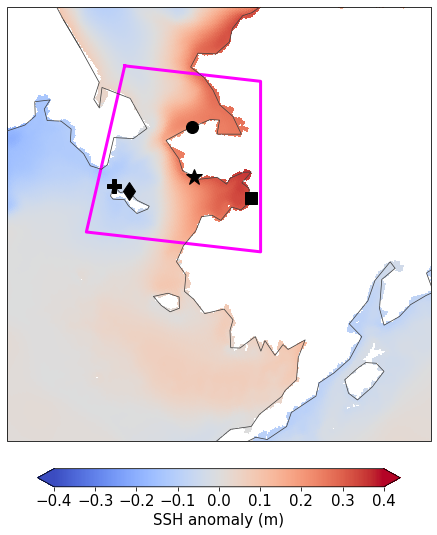

In [30]:
# set some of the plot info

# set info for this plot - just pattern 2a!
ds_plot = node_composite_all.sel(node=6)
data_masked = ds_plot.where(ocean.values > 0.5)
file_out = 'figure_6_ssh_anomaly_pattern_2a.png'
print(file_out)

# make plot
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(1,1,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
cs = ax.pcolormesh(lon2d.values, lat2d.values, data_masked.values,
        vmin=vmin_in, vmax=vmax_in, cmap=cmap_choice, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m', color='0.25', linewidth=0.75, zorder=10)
#plt.title('SSH',fontsize=15)

# Add primary village locations and names
for name, lonv, latv, shape,size in zip(village_names_1, village_lons_1, village_lats_1, village_shapes_1,village_sizes_1):
    ax.plot(lonv, latv,marker=shape,markersize=size,linestyle='none',color='black',label=name,zorder=100,transform=ccrs.PlateCarree())

## add Bering Sea "region" to map:
lon_pts = [box1_lonmin,box1_lonmax,box1_lonmax,box1_lonmin,box1_lonmin]
lat_pts = [box1_latmax,box1_latmax,box1_latmin,box1_latmin,box1_latmax]
ax.plot(lon_pts, lat_pts, color='magenta', linewidth=3,transform=ccrs.PlateCarree())

# colorbar stuff
cbar = fig.colorbar(cs, ax=ax, orientation='horizontal', ticks=ticks_1[:],
                    extend='both', pad=0.05, shrink=0.65)
cbar.ax.tick_params(labelsize=15)
cbar.set_label('SSH anomaly ('+units+')', fontsize=15)
    
# save figure
plt.savefig(file_out, bbox_inches='tight', dpi=200)
plt.savefig(dir_out+file_out, bbox_inches='tight', dpi=200)